# PathPack v0.8

v0.8 не меняет открывающий чанк файла из v0.4. Срез может занять только токены между этим чанком и следующим новым файлом. Блокнот читает прогон `output/v08_dev`. v0.4 остаётся основной версией: Function Recall ниже, а прирост Changed Line Recall приходится на одну задачу и интервал включает ноль.


In [1]:
from pathlib import Path
import gzip, json, sys
from collections import Counter
ROOT=Path.cwd().resolve()
if not (ROOT/'src').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from codegraph_rag.experiments import diagnostic_stem
def kinds(iid):
    path=ROOT/'output/v08_dev/diagnostics'/f'{diagnostic_stem(iid,"pathpack-v8",2048)}.json.gz'
    with gzip.open(path,'rt') as handle:
        doc=json.load(handle)
    selected=[item for item in doc['candidates'] if item.get('selected')]
    return Counter(item['representation'] for item in selected), doc['tokens_est']
for iid in ('astropy__astropy-8707','scikit-learn__scikit-learn-13124'):
    counts,tokens=kinds(iid)
    print(iid, 'tokens', tokens, dict(counts))


astropy__astropy-8707 tokens 2048 {'anchor': 9, 'slice': 8}
scikit-learn__scikit-learn-13124 tokens 2027 {'anchor': 10, 'slice': 7, 'whole': 1}


## Качество и бюджет

Кривые v0.4 и v0.8 читают `output/v08_dev`. Остальные методы взяты из уже посчитанных прогонов на тех же 20 задачах.


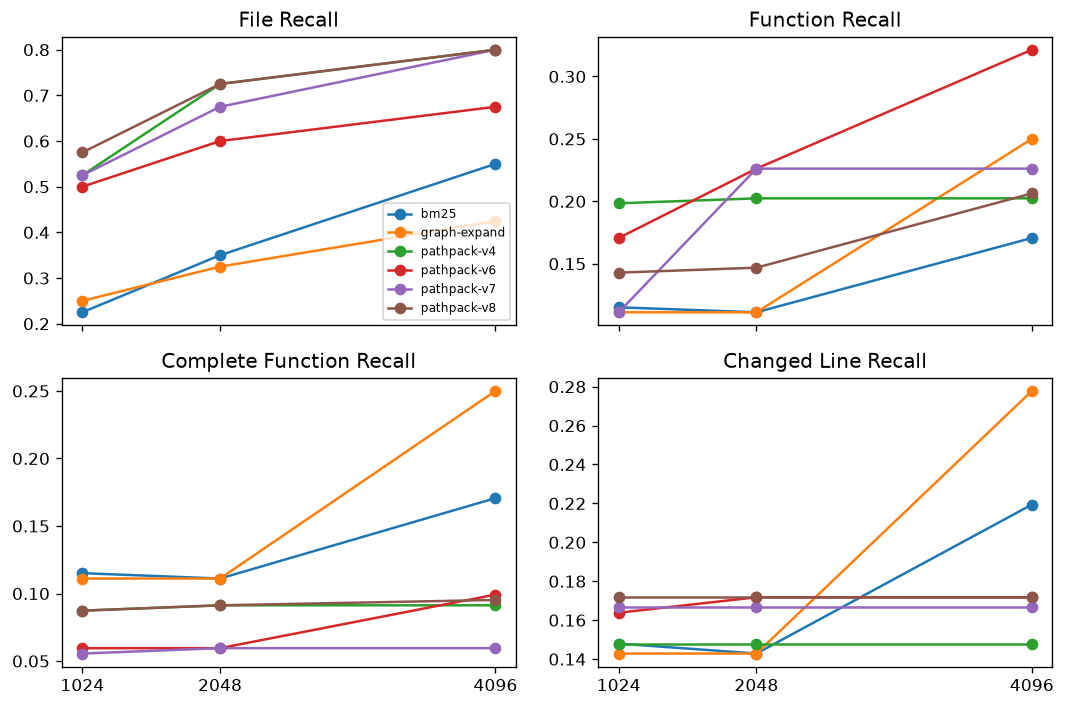

In [2]:
import csv
def rows(path):
    with open(ROOT/path) as handle:
        return list(csv.DictReader(handle))
dev=rows('output/v08_dev/summary.csv')
old=rows('output/v06_dev/summary.csv')
v7=rows('output/v07_dev/summary.csv')
metrics=[('file_recall','File Recall'),('function_recall','Function Recall'),
         ('complete_function_recall','Complete Function Recall'),('changed_line_recall','Changed Line Recall')]
series={'bm25':old,'graph-expand':old,'pathpack-v4':dev,'pathpack-v6':old,'pathpack-v7':v7,'pathpack-v8':dev}
fig,axes=plt.subplots(2,2,figsize=(9,6),sharex=True)
for ax,(key,title) in zip(axes.ravel(),metrics):
    for method,table in series.items():
        pts=[(int(row['budget']), float(row[key])) for row in table if row['method']==method]
        pts.sort()
        ax.plot([p[0] for p in pts],[p[1] for p in pts], marker='o', label=method)
    ax.set_title(title); ax.set_xticks([1024,2048,4096])
axes[0,0].legend(fontsize=7)
fig.tight_layout()


## Абляции и парное сравнение при 2048

`no-deepen` повторяет v0.4. `no-adaptive` совпадает с полным v0.8.


file_recall                    0.0000 [  0.000,   0.000] 0/20/0
function_recall               -0.0556 [ -0.167,   0.000] 0/17/1
complete_function_recall       0.0000 [  0.000,   0.000] 0/18/0
changed_line_recall            0.0238 [  0.000,   0.071] 1/13/0
tasks that differ
astropy__astropy-8707 changed_line_recall 0.0->0.3333333333333333
scikit-learn__scikit-learn-13124 function_recall 1.0->0.0


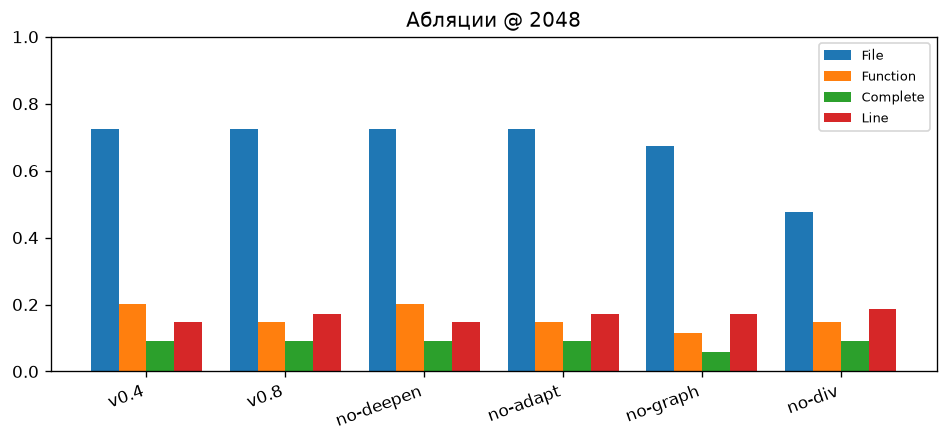

In [3]:
import json
from collections import defaultdict
import numpy as np
order=['pathpack-v4','pathpack-v8','pathpack-v8/no-deepen','pathpack-v8/no-adaptive','pathpack-v8/no-graph','pathpack-v8/no-diversity']
at={row['method']:row for row in dev if row['budget']=='2048'}
fig,ax=plt.subplots(figsize=(8,3.8))
x=np.arange(len(order)); width=0.2
for offset,key,label in ((-1.5,'file_recall','File'),(-0.5,'function_recall','Function'),
                         (0.5,'complete_function_recall','Complete'),(1.5,'changed_line_recall','Line')):
    ax.bar(x+offset*width, [float(at[name][key]) for name in order], width=width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(['v0.4','v0.8','no-deepen','no-adapt','no-graph','no-div'], rotation=20, ha='right')
ax.set_ylim(0,1); ax.legend(fontsize=8); ax.set_title('Абляции @ 2048')
fig.tight_layout()
from codegraph_rag.audit import paired_bootstrap
scores=[json.loads(line) for line in open(ROOT/'output/v08_dev/scores.jsonl')]
by=defaultdict(dict)
for row in scores:
    if row['budget']==2048:
        by[row['method']][row['instance_id']]=row
for metric in ('file_recall','function_recall','complete_function_recall','changed_line_recall'):
    left={i:row[metric] for i,row in by['pathpack-v8'].items() if row[metric] is not None}
    right={i:row[metric] for i,row in by['pathpack-v4'].items() if row[metric] is not None}
    stat=paired_bootstrap(left,right,iterations=2000,seed=42)
    lo,hi=stat['ci95']
    print(f"{metric:<28} {stat['difference']:8.4f} [{lo:7.3f}, {hi:7.3f}] {stat['wins']}/{stat['ties']}/{stat['losses']}")
print('tasks that differ')
for iid in sorted(by['pathpack-v8']):
    diffs=[]
    for metric in ('file_recall','function_recall','complete_function_recall','changed_line_recall'):
        if by['pathpack-v8'][iid][metric]!=by['pathpack-v4'][iid][metric]:
            diffs.append(f"{metric} {by['pathpack-v4'][iid][metric]}->{by['pathpack-v8'][iid][metric]}")
    if diffs:
        print(iid, '; '.join(diffs))


## Вывод

Ограничение промежутка удержало File Recall на уровне v0.4. Перераспределение хвоста сняло покрытие `StratifiedKFold._make_test_folds` в sklearn и добавило строки только в `astropy__astropy-8707`. Интервал этого прироста включает ноль. Holdout не запускался. `configs/pathpack_v08.yaml` после прогона не менялся.
